# NganyaFlow: data cleaning and model evaluation

This study uses NumPy and pandas to prepare arrival records for Kencom, Odeon
and the Railways area at Nairobi Central Station. It then trains a quantile
regression forest (QRF) to predict how long a passenger would wait for the
next arrival.

The analysis uses the project's synthetic validation dataset. We check the
records, work through a separate example of common data errors, and test the
model on dates kept out of training. Performance is measured in minutes,
alongside R², the share of predictions within a chosen tolerance, and
prediction interval coverage.

Run the cells in order with the project virtual environment. The notebook
saves its results locally and runs without Docker or a server connection.
It leaves the source data and active server model unchanged. See the
[setup guide](README.md) and [AI report](../../docs/ai-report.md).

## Start here: the question we want to answer

A passenger arrives at Kencom and asks, "How long until the next vehicle?"
NganyaFlow needs to turn earlier arrival records into a useful estimate.
In this notebook, we check those records, teach a model using earlier days,
then see how well it predicts waits on later days.

An arrival time and a passenger's waiting time are different. If vehicles arrive
at 7:00, 7:06 and 7:14, someone asking at 7:08 waits 6 minutes. At that moment,
we know the last gap was 6 minutes and that 2 minutes have passed since the
latest arrival. We only learn the correct answer, 6 minutes, once the 7:14
arrival happens. Recorded history lets us create examples like this to train
and test the model.

The numbered explanations below follow the 15 code cells in reading order.
Jupyter's bracketed execution numbers can differ if you rerun individual cells.
The existing technical notes give more detail after you understand each step.

A few Python terms will help:

- A **variable**, such as `cleaned`, is a name for something the code stores.
- A **function**, such as `clean_arrivals(...)`, is a reusable set of instructions.
- `import` loads a tool that Python can use. pandas handles tables, NumPy does
  numerical calculations, and Matplotlib draws charts.
- A pandas **DataFrame** is a table with rows and columns. A **Series** is one
  column or a labelled list of values.
- `display(...)` shows a table; `print(...)` shows a message. `assert` checks a
  condition and stops the cell if it fails. An assertion checks a particular
  assumption; it is not proof that every part of a dataset is correct.
- **JSON** stores structured records, while **CSV** stores a table that you can
  also open in a spreadsheet. Saving a file preserves it for later use.

## 1. Set up the environment and load the data

### Code cell 1: prepare the tools

We first give Python access to the tools needed for the study. pandas will
organize the arrival records, NumPy will calculate errors, and Matplotlib
will draw the graphs. The cell also finds the project folder and creates a
place to save results.

The package-version table records which editions of those tools were used.
The interpreter path tells us which Python installation is running. SHA256
is a file fingerprint: comparing it before and after the study helps us check
that the input file has not changed. It does not tell us whether the data is
truthful or high quality.

No learning happens here. We are setting up the workspace so the remaining
steps use the intended tools and dataset.

In [1]:
import hashlib
import importlib.metadata as metadata
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Find the repository from either its root or this notebook's directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'server/src/nganyaflow/ml.py').is_file())

sys.path.insert(0, str(ROOT / 'server/src'))
from nganyaflow.datasets import validate_bundle
from nganyaflow.schemas import Catalog
from nganyaflow.ml import build_samples, train

OUT = ROOT / 'server/notebooks/results'
OUT.mkdir(parents=True, exist_ok=True)
DATA = ROOT / 'server/data/examples/nairobi-cbd-synthetic-v1.json'
source_hash = hashlib.sha256(DATA.read_bytes()).hexdigest()

pd.set_option('display.max_columns', 16)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
display(pd.Series({p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'quantile-forest', 'notebook']}, name='installed version').to_frame())
print('Interpreter:', sys.executable)
print('Dataset SHA256:', source_hash)

,installed version
numpy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
quantile-forest,1.4.2
notebook,7.6.4


Interpreter: C:\Users\manot\OneDrive\Documents\GitHub\NganyaFlow\.venv\Scripts\python.exe
Dataset SHA256: 27a8c9d1f5e89515e1cf59346308cb96455c75d2a9a13cbdac555175785c0168


### Code cell 2: read the records and connect them to their sessions

An **observation** records an event such as one vehicle arriving. A **session**
is a continuous period during which an enumerator watches a particular stage,
route and direction. The session tells us where an observation belongs and
when collection started and ended.

This cell opens the dataset and the **catalog**, the list of supported stages
and services. It uses the server's checks, then joins observations to their
sessions so each table row has both the arrival and its context. Many arrivals
may belong to one session; each arrival must have one matching session.

Look for 1,049 observations and 84 sessions. `missing` counts empty entries;
`unique` counts distinct values; `dtype` describes how Python stores a column,
such as text or numbers. **Provenance** simply means where the dataset came
from. These checks help us avoid learning from records whose time or location
we cannot interpret.

In [2]:
bundle = json.loads(DATA.read_text(encoding='utf-8'))
catalog = Catalog.model_validate_json((ROOT / 'server/data/reference/catalog.json').read_text(encoding='utf-8'))


# Reuse the same schema/catalog/provenance validation as the admin importer.
provenance, valid_sessions, session_ends, valid_events = validate_bundle(bundle, catalog)
assert provenance['data_kind'] == 'synthetic'
display(pd.Series({k: provenance[k] for k in ['dataset_id', 'data_kind', 'description', 'period']}).to_frame('value'))

sessions = pd.json_normalize(bundle['sessions'])
events = pd.json_normalize(bundle['observations'])
assert sessions['id'].is_unique
raw = events.merge(sessions.rename(columns={'id': 'session_id'}), on='session_id', how='left', validate='many_to_one', indicator=True)

print(f'{len(events):,} observations; {len(sessions)} completed sessions')
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'unique': raw.nunique(dropna=False)}))

,value
dataset_id,nairobi-cbd-synthetic-v1
data_kind,synthetic
description,Real Nairobi CBD place names; all arrival time...
period,2026-10-05 to 2026-10-18


1,049 observations; 84 completed sessions


,id,session_id,observed_at,event_type,occupancy,stage_id,route_id,direction,started_at,ended_at,data_kind,dataset_id,_merge
0,88cad105-1747-573a-a84d-2020818710bb,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T07:01:00+03:00,arrival,unknown,kencom,cbd-study-simulated,townbound,2026-10-05T07:00:00+03:00,2026-10-05T08:30:00+03:00,synthetic,nairobi-cbd-synthetic-v1,both
1,04dbad73-3a2f-5646-9e78-af578c6df484,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T07:06:45+03:00,arrival,unknown,kencom,cbd-study-simulated,townbound,2026-10-05T07:00:00+03:00,2026-10-05T08:30:00+03:00,synthetic,nairobi-cbd-synthetic-v1,both
2,fb4cddfb-33de-5d94-923b-cf971c067f7c,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T07:13:29+03:00,arrival,unknown,kencom,cbd-study-simulated,townbound,2026-10-05T07:00:00+03:00,2026-10-05T08:30:00+03:00,synthetic,nairobi-cbd-synthetic-v1,both
3,20ff747f-a099-57ab-b6c7-e9f3e15ce405,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T07:19:03+03:00,arrival,unknown,kencom,cbd-study-simulated,townbound,2026-10-05T07:00:00+03:00,2026-10-05T08:30:00+03:00,synthetic,nairobi-cbd-synthetic-v1,both
4,66035c56-1479-53b5-b15f-b5b1d4abc416,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T07:24:38+03:00,arrival,unknown,kencom,cbd-study-simulated,townbound,2026-10-05T07:00:00+03:00,2026-10-05T08:30:00+03:00,synthetic,nairobi-cbd-synthetic-v1,both


,dtype,missing,unique
id,str,0,1049
session_id,str,0,84
observed_at,str,0,991
event_type,str,0,1
occupancy,str,0,1
stage_id,str,0,3
route_id,str,0,1
direction,str,0,1
started_at,str,0,28
ended_at,str,0,28


## 2. Clean the arrival records

The cleaning function trims whitespace and converts timestamps to UTC.
It checks that each arrival belongs to a known session, falls within that
session's start and end times, and has a supported stage, route and direction.
Records must also match the dataset's source information.

Missing or invalid timestamps are rejected, including timestamps without
a time zone. When the same observation ID has conflicting details, all its
versions are set aside for review. Exact retries are reduced to one record,
as are repeated arrivals at the same time within a session. Each rejected
row keeps a reason so we can trace what happened.

Waiting times are left as recorded: missing values are not filled in,
timestamps are not guessed, and long waits are not discarded simply for
being unusual. The server's import validator has already checked the
bundle's schema, sessions and catalog. This analysis works with arrivals;
departures fall outside its scope.

### Code cell 3: check which arrivals are usable

A repeated upload must not make the model believe two vehicles arrived when
only one did. An arrival recorded after its observation session ended also
needs attention. This cell defines the cleaning rules, applies them, and
separates accepted records from rejected ones.

A **timestamp** is a date and time. UTC gives us a common time reference;
Nairobi local time is used later when grouping records by day. A timestamp
without a time zone is ambiguous, so this code rejects it instead of guessing.
**Deduplication** means keeping one copy of a repeated record. Conflicting
versions are set aside with an explanation.

The **audit** is the count of accepted rows and rejection reasons. Here it
should show 1,049 accepted arrivals and zero rejections. Cleaning can confirm
that records already pass the rules; it does not have to remove something.
CSV files preserve the cleaned table and audit for review.

In [3]:
TEXT = ['id', 'session_id', 'stage_id', 'route_id', 'direction',
        'data_kind', 'dataset_id', 'event_type']
allowed = {(stage, route.id, direction) for route in catalog.routes
           for stage in route.stage_ids for direction in route.directions}

def clean_arrivals(frame):
    data = frame.copy().reset_index(drop=True)
    data.insert(0, 'source_row', np.arange(len(data)))
    reasons = pd.Series('', index=data.index, dtype='string')

    def flag(mask, reason):
        mask = pd.Series(mask, index=data.index).fillna(True)
        reasons.loc[mask & reasons.eq('')] = reason

    for col in TEXT:
        data[col] = data[col].astype('string').str.strip()
    flag(data[TEXT].isna().any(axis=1) | data[TEXT].eq('').any(axis=1),
         'missing required value')
    # UTC conversion alone would silently assume UTC for a naive timestamp.
    for col in ['observed_at', 'started_at', 'ended_at']:
        text = data[col].astype('string').str.strip()
        aware = text.str.contains(r'(?:Z|[+-]\d{2}:\d{2})$', regex=True, na=False)
        parsed = pd.to_datetime(text, utc=True, errors='coerce', format='ISO8601')
        flag(~aware | parsed.isna(), 'invalid or timezone-naive timestamp')
        data[col] = parsed
    flag(data['_merge'].ne('both'), 'unknown session')
    flag(data['event_type'].ne('arrival'), 'not an arrival')
    flag(data['data_kind'].ne(provenance['data_kind']) |
         data['dataset_id'].ne(provenance['dataset_id']), 'provenance mismatch')
    flag([tuple(row) not in allowed for row in
          data[['stage_id', 'route_id', 'direction']].itertuples(index=False, name=None)],
         'unsupported stage/route/direction')
    flag((data['ended_at'] < data['started_at']) |
         ((data['ended_at'] - data['started_at']).dt.total_seconds() > 43200),
         'invalid session duration')
    flag((data['observed_at'] < data['started_at']) |
         (data['observed_at'] > data['ended_at']), 'outside session')

    payload_cols = [*TEXT, 'observed_at', 'started_at', 'ended_at', 'occupancy']
    unique_payloads = data.drop_duplicates(subset=payload_cols)
    conflicting_ids = unique_payloads.loc[
        unique_payloads.duplicated('id', keep=False), 'id']
    flag(data['id'].isin(conflicting_ids), 'conflicting observation ID')
    # Only valid rows take part in retry deduplication.
    eligible = data.loc[reasons.eq('')]
    duplicates = eligible.duplicated(payload_cols, keep='first')
    flag(data.index.isin(eligible.index[duplicates]), 'exact duplicate retry')
    eligible = data.loc[reasons.eq('')]
    duplicates = eligible.duplicated(['session_id', 'observed_at'], keep='first')
    flag(data.index.isin(eligible.index[duplicates]), 'duplicate arrival instant')

    rejected = data.loc[reasons.ne('')].copy()
    rejected['reason'] = reasons.loc[rejected.index]
    cleaned = data.loc[reasons.eq('')].sort_values(
        ['session_id', 'observed_at'], kind='stable').copy()
    assert len(cleaned) + len(rejected) == len(frame)
    audit = pd.concat([pd.Series({'accepted': len(cleaned)}),
                       rejected['reason'].value_counts()]).rename('rows').to_frame()
    return cleaned, rejected, audit

cleaned, rejected, cleaning_audit = clean_arrivals(raw)
display(cleaning_audit)
assert len(cleaned) == 1049 and len(rejected) == 0
cleaned.to_csv(OUT / 'cleaned_arrivals.csv', index=False)
rejected.to_csv(OUT / 'rejected_arrivals.csv', index=False)
cleaning_audit.to_csv(OUT / 'cleaning_audit.csv')
print('The supplied synthetic source is already clean under these checks.')

,rows
accepted,1049


The supplied synthetic source is already clean under these checks.


### Check how cleaning handles common errors

To see the cleaning rules at work, we add seven rows to a copy of the data:
an exact retry, a missing timestamp, a malformed timestamp, a timestamp
without a time zone, an arrival outside its session, an unknown stage,
and a repeated arrival time with a different ID.

This example stays separate from the training data. The original JSON file
is left unchanged.

### Code cell 4: test the cleaning rules with known mistakes

Since the source passes the checks, we make a separate copy with seven added
problems. These include missing or invalid times, a duplicate, an unknown
stage and an arrival outside its session. Knowing which problems we inserted
gives us a way to check whether the cleaning function catches them.

Read the rejection table's `reason` column to see why each added row was
removed. The assertions check that all seven were rejected and that the
original accepted arrival IDs remain.

This resembles checking a mobile synchronization workflow: a retry may resend
an event, but it should still count once. The example checks these seven cases;
it does not test every possible mistake. This copy never enters training.

In [4]:
examples = []
for i in range(7):
    row = raw.iloc[0].copy()
    if i:
        row['id'] = f'teaching-only-{i}'
    examples.append(row)
examples[1]['observed_at'] = None
examples[2]['observed_at'] = 'not-a-date'
examples[3]['observed_at'] = '2026-10-05T07:15:00'
examples[4]['observed_at'] = '2026-10-05T23:00:00+03:00'
examples[5]['stage_id'] = 'unknown-stage'
dirty_demo = pd.concat([raw, pd.DataFrame(examples)], ignore_index=True)
demo_clean, demo_rejected, demo_audit = clean_arrivals(dirty_demo)
display(demo_audit)
display(demo_rejected[['source_row', 'id', 'observed_at', 'reason']])
assert len(demo_clean) == len(cleaned) and len(demo_rejected) == 7
assert set(demo_clean['id']) == set(cleaned['id'])
demo_rejected.to_csv(OUT / 'teaching_only_rejections.csv', index=False)

,rows
accepted,1049
invalid or timezone-naive timestamp,3
exact duplicate retry,1
outside session,1
unsupported stage/route/direction,1
duplicate arrival instant,1


,source_row,id,observed_at,reason
1049,1049,88cad105-1747-573a-a84d-2020818710bb,2026-10-05 04:01:00+00:00,exact duplicate retry
1050,1050,teaching-only-1,NaT,invalid or timezone-naive timestamp
1051,1051,teaching-only-2,NaT,invalid or timezone-naive timestamp
1052,1052,teaching-only-3,2026-10-05 07:15:00+00:00,invalid or timezone-naive timestamp
1053,1053,teaching-only-4,2026-10-05 20:00:00+00:00,outside session
1054,1054,teaching-only-5,2026-10-05 04:01:00+00:00,unsupported stage/route/direction
1055,1055,teaching-only-6,2026-10-05 04:01:00+00:00,duplicate arrival instant


## 3. Explore arrivals and headways

### Code cell 5: understand the gaps between vehicles

**Headway** means the time between consecutive vehicle arrivals. If two
vehicles reach Odeon at 7:00 and 7:06, their headway is 6 minutes. This cell
calculates gaps within each session, then summarizes the records by stage.
It never treats an overnight break between sessions as a vehicle gap.

The bar chart shows how many arrivals each stage contributes. The histogram
groups headways into ranges: taller bars mean more gaps fall in that range.
The first arrival in each session has no preceding arrival to compare with,
so its headway is blank.

In the summary, **median** is the middle value after sorting. A **percentile**
marks a position in that sorted list; roughly 90% of values are at or below
the 90th percentile. This helps us see whether most gaps are short, whether
some are much longer, and whether the stages have different patterns.

,arrivals,sessions,days,median_headway_minutes
stage_id,,,,
kencom,453,28,14,5.616667
odeon,341,28,14,7.350000
railways,255,28,14,9.450000


,headway_minutes
count,965.000000
mean,7.366684
std,2.862367
min,2.000000
10%,4.106667
50%,6.950000
90%,11.550000
max,18.516667


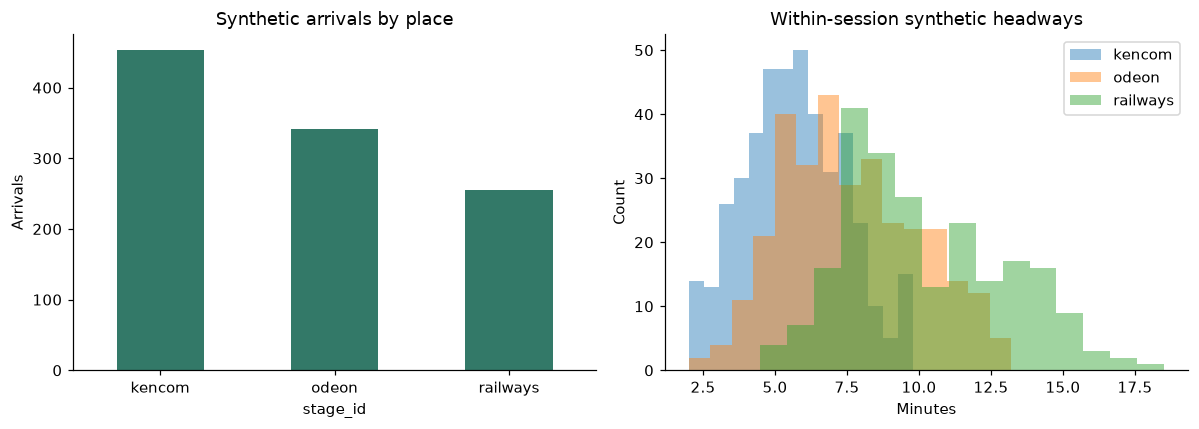

In [5]:
cleaned['local_day'] = cleaned['observed_at'].dt.tz_convert('Africa/Nairobi').dt.date
cleaned['headway_minutes'] = (
    cleaned.groupby('session_id')['observed_at'].diff().dt.total_seconds() / 60)
summary = cleaned.groupby('stage_id').agg(
    arrivals=('id', 'size'), sessions=('session_id', 'nunique'),
    days=('local_day', 'nunique'), median_headway_minutes=('headway_minutes', 'median'))
display(summary)
display(cleaned['headway_minutes'].describe(percentiles=[.1, .5, .9]).to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary['arrivals'].plot.bar(ax=axes[0], color='#337968', rot=0,
                           title='Synthetic arrivals by place', ylabel='Arrivals')
for stage, rows in cleaned.groupby('stage_id'):
    axes[1].hist(rows['headway_minutes'].dropna(), bins=15, alpha=.45, label=stage)
axes[1].set(title='Within-session synthetic headways', xlabel='Minutes', ylabel='Count')
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Calculate waiting times and split the data

We use three consecutive arrivals, `(previous, current, following)`, from
the same session. Starting one minute after `current`, we create a query
every minute until `following`. All times are measured in minutes:

- `last_headway = current − previous`
- `elapsed = query − current`
- `wait = following − query`

The following arrival gives us the answer used to train and test the model.
It is excluded from the input features because it would not yet be known
when a passenger asks for a prediction.

The backend's sample builder keeps queries within one session and one local
date. It excludes the unobserved end of a session and intervals where either
headway exceeds 120 minutes. The tree model does not need feature scaling.

We use the same sample builder and trainer as the server. The last three
complete Nairobi dates are reserved for testing, and earlier dates are used
for training. Keeping dates together avoids spreading closely related
minute queries across both sets. Category encoding is fitted on the training
data only.

### Code cell 6: turn arrivals into passenger questions

Arrival records do not directly say how long someone asking between arrivals
would wait. The sample builder creates those questions at one-minute steps.
Each **sample** is one question, its available information, and the correct
waiting time obtained from the next recorded arrival.

**Features** are the clues given to the model: stage, route, direction, time
of day, weekday, time since the latest arrival, and the preceding headway.
The **target**, also called the label, is the wait we want it to predict.
Keeping the next arrival out of the features prevents **data leakage**, which
would give the model information unavailable when a passenger asks.

We keep 4,684 questions from 11 earlier dates for training and 1,259 questions
from the last 3 dates for testing. **Held out** means kept out of fitting.
One arrival can help create several minute-by-minute questions, which is why
there are more questions than arrivals. These questions are related, so we
keep complete dates and sessions together instead of randomly mixing rows.

In [6]:
# Preserve canonical server serialization and input order for reproducible training.
accepted_ids = set(cleaned['id'])
records = [dict(valid_sessions[str(event.session_id)].model_dump(mode='json'),
                **event.model_dump(mode='json'))
           for event in valid_events if str(event.id) in accepted_ids]
samples = build_samples(records)
sample_frame = pd.DataFrame([
    dict(sample['features'], day=sample['day'], session_id=sample['session_id'],
         query_at=sample['query_at'], actual_wait_minutes=sample['wait'])
    for sample in samples])
dates = sorted(sample_frame['day'].unique())
test_dates = dates[-3:]
fit_rows = sample_frame.loc[sample_frame['day'] < test_dates[0]]
test_rows = sample_frame.loc[sample_frame['day'] >= test_dates[0]]
assert set(fit_rows['session_id']).isdisjoint(test_rows['session_id'])
assert fit_rows['day'].max() < test_rows['day'].min()
display(pd.DataFrame([
    {'partition': name, 'queries': len(rows), 'sessions': rows['session_id'].nunique(),
     'days': rows['day'].nunique(), 'first_day': rows['day'].min(),
     'last_day': rows['day'].max()}
    for name, rows in [('training', fit_rows), ('held out', test_rows)]]))
display(sample_frame.head())
assert (len(fit_rows), len(test_rows)) == (4684, 1259)

,partition,queries,sessions,days,first_day,last_day
0,training,4684,66,11,2026-10-05,2026-10-15
1,held out,1259,18,3,2026-10-16,2026-10-18


,stage_id,route_id,direction,hour,weekday,elapsed_minutes,last_headway_minutes,day,session_id,query_at,actual_wait_minutes
0,kencom,cbd-study-simulated,townbound,7.116667,0,1.0,5.75,2026-10-05,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T04:07:45+00:00,5.733333
1,kencom,cbd-study-simulated,townbound,7.133333,0,2.0,5.75,2026-10-05,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T04:08:45+00:00,4.733333
2,kencom,cbd-study-simulated,townbound,7.150000,0,3.0,5.75,2026-10-05,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T04:09:45+00:00,3.733333
3,kencom,cbd-study-simulated,townbound,7.166667,0,4.0,5.75,2026-10-05,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T04:10:45+00:00,2.733333
4,kencom,cbd-study-simulated,townbound,7.183333,0,5.0,5.75,2026-10-05,a02e4848-ac34-52cd-92ad-546bb8d6abac,2026-10-05T04:11:45+00:00,1.733333


## 5. Train the quantile regression forest

The forest has 100 trees, a minimum leaf size of 5 and a random seed of 42.
It retains all leaf samples, and every input column is eligible at each
split (`max_features=1.0`).

For each query, the model estimates the 10th, 50th and 90th percentiles of
waiting time. We use the median as the point prediction and the outer two
percentiles as a nominal 80% prediction interval. The trees use squared
error to choose their splits; pinball loss is used later to evaluate the
quantile predictions.

Training also runs the shuffled-label control, learning curve and
permutation checks. The resulting model is saved under `results/` for
this analysis, leaving the server's active model unchanged.

### Code cell 7: teach the model to estimate a wait

**Training** means finding patterns between the clues and the known answers
in the earlier data. A **decision tree** repeatedly divides examples according
to their features, for example by elapsed time or preceding headway. A forest
combines many trees; ours has 100. Its minimum leaf size of 5 limits how small
the groups at the ends of the trees can become.

A **quantile regression forest** uses the waiting times represented in those
groups to estimate several positions in the range of possible waits. We ask
for a lower estimate, a middle estimate (the median), and an upper estimate.
The outer estimates form the proposed waiting-time range.

The random seed makes the training choices repeatable. **Encoding** converts
names such as stage IDs into numeric columns a model can use. An **artifact**
is the saved trained model and its supporting information; it is not a new
algorithm. This cell writes that file locally and reads the test predictions.
It does not replace the active server model or learn continuously by itself.

In [7]:
artifact_path = OUT / 'notebook-qrf.joblib'
report = train(records, artifact_path, min_samples=30, min_days=3,
               test_days=3, diagnostics=True)
artifact = joblib.load(artifact_path)  # Only this notebook's newly created artifact.
print(type(artifact['model']).__name__, '| trees:', len(artifact['model'].estimators_))
print('Model version:', report['model_version'], '| provenance:', report['data_kind'])
print('Encoded columns:', artifact['vectorizer'].get_feature_names_out())
pred = pd.read_csv(artifact_path.with_suffix('.predictions.csv'))
assert len(pred) == len(test_rows) == report['test_samples']
assert report['train_days'] == sorted(fit_rows['day'].unique())
assert report['test_days'] == test_dates
assert np.isfinite(pred.select_dtypes(include='number').to_numpy()).all()
assert (pred['lower_minutes'] <= pred['median_minutes']).all()
assert (pred['median_minutes'] <= pred['upper_minutes']).all()

RandomForestQuantileRegressor | trees: 100
Model version: 6180f85b9e302bd7 | provenance: synthetic
Encoded columns: ['direction=townbound' 'elapsed_minutes' 'hour' 'last_headway_minutes'
 'route_id=cbd-study-simulated' 'stage_id=kencom' 'stage_id=odeon'
 'stage_id=railways' 'weekday']


## 6. Measure prediction accuracy

With `error = prediction − actual wait`, MAE tells us how far predictions
miss by on average. RMSE gives more weight to large misses. Both are
measured in minutes, and lower values are better.

R² compares squared error with predicting the mean wait of the test set.
Higher values are better; a negative value means the model does worse than
that reference. The percentages within ±1 and ±2 minutes answer a more
practical question: how often is the prediction close enough under each
chosen tolerance?

NumPy calculates these measures for the QRF and two baselines on the same
test queries. The historical baseline uses the median training wait for
each stage, route and direction. The last-headway baseline predicts
`max(0, preceding headway − elapsed)` using information available at the
time of the query.

Interval coverage measures how often the observed wait falls between the
lower and upper predictions. It is assessed separately from point accuracy.

### Code cell 8: measure how far the predictions miss

We now compare predictions with known answers on the later test dates.
MAE averages the size of the mistakes: predicting 5 minutes when the wait is
3 minutes gives a 2-minute absolute error. Our MAE of about 0.939 minutes
means the average miss is about 56 seconds across these test questions.
It does not mean every prediction misses by 56 seconds.

**RMSE** is another error measure that gives extra weight to large mistakes.
**R²** compares squared prediction error with always predicting the test set's
average wait. Here it is about 0.844, or 84.4% of the variation accounted for.
It is not the percentage of correct predictions. The ±1 and ±2 minute columns
directly count predictions within those tolerances; about 90.39% are within
2 minutes.

A **baseline** is a simpler method used for comparison. One always uses the
historical median for that service; the other assumes the next gap will match
the last gap and subtracts time already elapsed. If these simple methods do
as well as the forest, its extra complexity may not help. Compare each row
using the same measure: lower MAE and RMSE are better.

In [8]:
truth = pred['actual_wait_minutes'].to_numpy()

def score(actual, prediction):
    error = np.asarray(prediction) - np.asarray(actual)
    sst = np.sum((actual - np.mean(actual)) ** 2)
    return {'MAE (min)': np.mean(np.abs(error)),
            'RMSE (min)': np.sqrt(np.mean(error ** 2)),
            'R²': 1 - np.sum(error ** 2) / sst if sst > 0 else np.nan,
            'Within ±1 min (%)': 100 * np.mean(np.abs(error) <= 1),
            'Within ±2 min (%)': 100 * np.mean(np.abs(error) <= 2)}

columns = {'QRF median': 'median_minutes',
           'Historical median': 'historical_median_minutes',
           'Last headway': 'last_headway_minutes'}
comparison = pd.DataFrame({name: score(truth, pred[col].to_numpy())
                           for name, col in columns.items()}).T
display(comparison.round(4))
np.testing.assert_allclose(comparison.loc['QRF median', 'MAE (min)'], report['mae_minutes'])
for name, field in [('Historical median', 'historical_median_mae_minutes'),
                    ('Last headway', 'last_headway_mae_minutes')]:
    np.testing.assert_allclose(comparison.loc[name, 'MAE (min)'], report[field])
comparison.to_csv(OUT / 'model_comparison.csv')
improvement = 100 * (1 - report['mae_minutes'] / report['historical_median_mae_minutes'])
display(Markdown(f'On these **synthetic held-out queries**, QRF MAE is '
                 f'**{report["mae_minutes"]:.3f} minutes** '
                 f'({report["mae_minutes"] * 60:.1f} seconds); '
                 f'**{improvement:.1f}% lower** than the historical-median baseline.'))

,MAE (min),RMSE (min),R²,Within ±1 min (%),Within ±2 min (%)
QRF median,0.9387,1.1699,0.8445,61.0802,90.3892
Historical median,2.2110,2.8277,0.0914,27.5616,53.6934
Last headway,1.0179,1.2591,0.8198,54.3288,89.2772


On these **synthetic held-out queries**, QRF MAE is **0.939 minutes** (56.3 seconds); **57.5% lower** than the historical-median baseline.

### Code cell 9: check whether the predicted range is useful

NganyaFlow can show uncertainty alongside a single estimate. For example,
"about 5 minutes, with an estimated range of 3 to 7 minutes" gives a passenger
more information than a point estimate alone. Those numbers are an example;
the model calculates its own range for each query.

The **10th and 90th quantiles** are the model's lower and upper estimates.
The range between them aims to contain 80% of waits. **Coverage** is the share
of test answers actually inside those ranges. **Nominal** means the intended
coverage, 80%; **observed** means the measured result, about 80.06% here.
**Width** is upper minus lower, averaging about 3.10 minutes. A very wide
range may cover many answers while giving little useful guidance.

**Pinball loss** scores each quantile, penalizing errors differently depending
on which side of its intended boundary the actual wait falls. Lower is better.
Read coverage and width together; neither tells us the percentage of point
predictions that are correct.

In [9]:
low = pred['lower_minutes'].to_numpy()
high = pred['upper_minutes'].to_numpy()
covered = (truth >= low) & (truth <= high)

def pinball(actual, prediction, q):
    residual = actual - prediction
    return np.mean(np.maximum(q * residual, (q - 1) * residual))

interval_metrics = pd.Series({
    'Nominal coverage (%)': 80.0,
    'Observed coverage (%)': 100 * np.mean(covered),
    'Mean interval width (min)': np.mean(high - low),
    **{f'Pinball loss q={q} (min)': pinball(truth, pred[col].to_numpy(), q)
       for q, col in [(0.1, 'lower_minutes'), (0.5, 'median_minutes'),
                      (0.9, 'upper_minutes')]}})
display(interval_metrics.to_frame('value').round(4))
np.testing.assert_allclose(np.mean(covered), report['empirical_coverage'])
np.testing.assert_allclose(np.mean(high - low), report['mean_interval_width_minutes'])
for q, col in [(0.1, 'lower_minutes'), (0.5, 'median_minutes'), (0.9, 'upper_minutes')]:
    np.testing.assert_allclose(pinball(truth, pred[col].to_numpy(), q),
                               report['pinball_loss'][str(q)])
interval_metrics.to_csv(OUT / 'interval_metrics.csv')
print('Coverage is the fraction of actual waits inside the predicted interval.')

,value
Nominal coverage (%),80.0000
Observed coverage (%),80.0635
Mean interval width (min),3.1015
Pinball loss q=0.1 (min),0.1856
Pinball loss q=0.5 (min),0.4694
Pinball loss q=0.9 (min),0.2246


Coverage is the fraction of actual waits inside the predicted interval.


### Code cell 10: check performance at each stage and on each day

One overall score can hide where passengers receive poorer estimates.
This cell groups the test questions first by stage and then by date,
calculating the number of questions, MAE and interval coverage for each group.

Kencom's MAE is about 0.873 minutes, Odeon's is 0.881, and Railways' is 1.073.
Their coverage figures also differ. This tells us where to investigate before
relying on the same model settings across all stages.

The coverage column is a fraction: 0.77 means about 77%. A stage with fewer
test questions contributes less evidence, so read the query counts alongside
the scores. Differences in this dataset do not by themselves explain what
causes the errors.

In [10]:
pred['absolute_error_minutes'] = np.abs(pred['median_minutes'] - truth)
pred['covered'] = covered
for group in ['stage_id', 'day']:
    table = pred.groupby(group).agg(
        queries=('absolute_error_minutes', 'size'),
        mae_minutes=('absolute_error_minutes', 'mean'),
        coverage=('covered', 'mean'))
    display(table.round(4))
    table.to_csv(OUT / f'metrics_by_{group}.csv')

,queries,mae_minutes,coverage
stage_id,,,
kencom,439,0.8734,0.7699
odeon,424,0.8813,0.7807
railways,396,1.0725,0.8561


,queries,mae_minutes,coverage
day,,,
2026-10-16,429,0.9154,0.7879
2026-10-17,421,0.9827,0.7981
2026-10-18,409,0.9179,0.8166


## 7. Plot the errors and prediction intervals

### Code cell 11: see the errors instead of only reading scores

The first figure shows three views of the same test results. Shorter bars
mean lower average errors. In the scatter plot, each dot is a question;
dots on the dashed diagonal have a predicted wait equal to the actual wait.
Dots farther from that line are larger misses.

The error histogram shows how mistakes are distributed. Positive values mean
we predicted a longer wait than occurred; negative values mean we predicted
a shorter wait. This distinction matters to a passenger deciding when to
reach a stage.

The second figure follows one Kencom session. The black line is the recorded
answer, the green line is the predicted median, and the shaded band is the
predicted range. Black-line points outside the band are waits the interval
missed. The horizontal axis counts query points within that session. Waits
fall as an arrival approaches, then rise again after a new arrival.

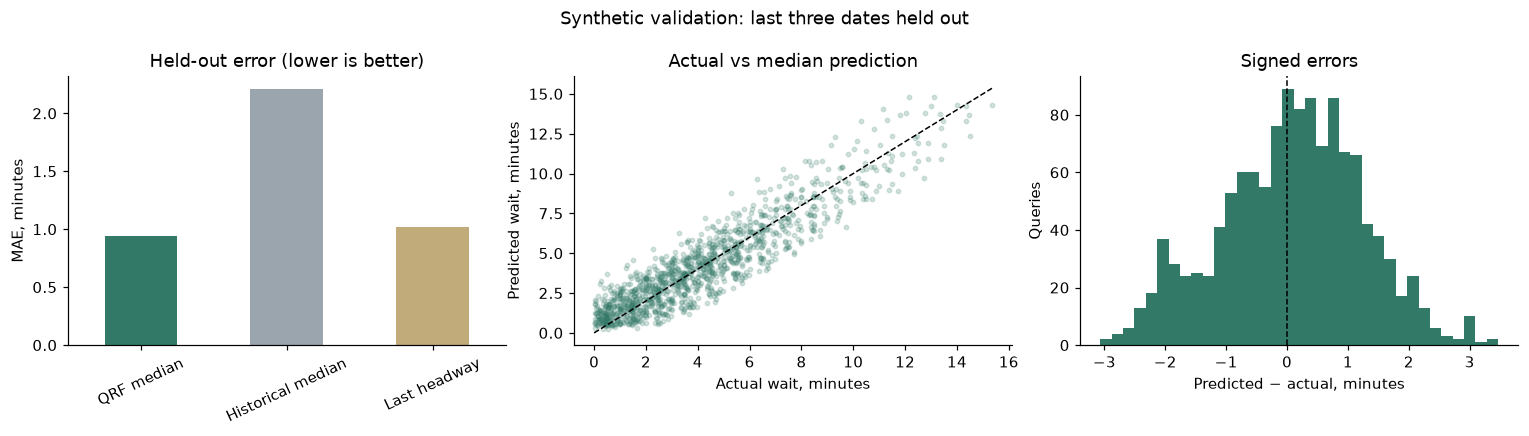

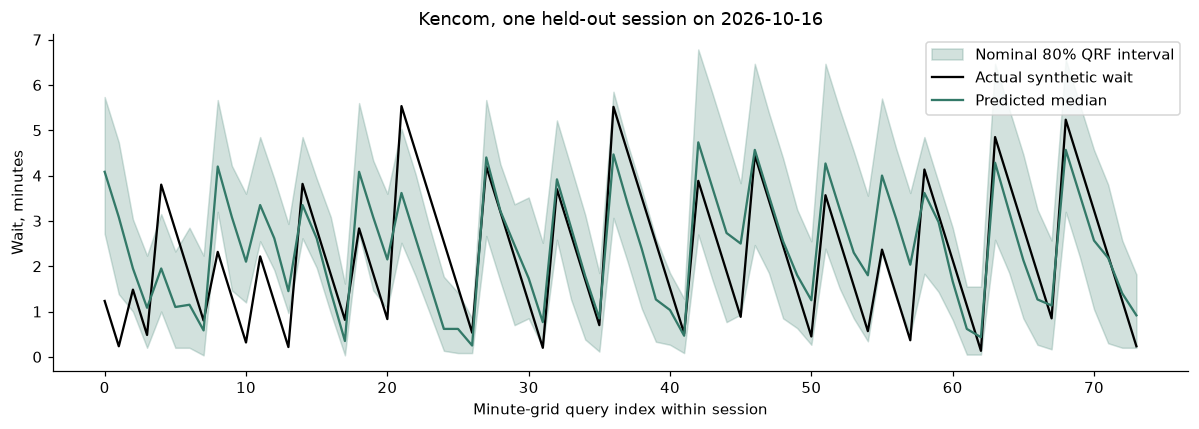

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
comparison['MAE (min)'].plot.bar(ax=axes[0], rot=25, color=['#337968', '#9aa5ad', '#c2ab7b'])
axes[0].set(title='Held-out error (lower is better)', ylabel='MAE, minutes', xlabel='')
axes[1].scatter(truth, pred['median_minutes'], s=8, alpha=.2, color='#337968')
limit = max(truth.max(), pred['median_minutes'].max())
axes[1].plot([0, limit], [0, limit], '--', color='black', linewidth=1)
axes[1].set(title='Actual vs median prediction', xlabel='Actual wait, minutes',
            ylabel='Predicted wait, minutes')
axes[2].hist(pred['median_minutes'] - truth, bins=35, color='#337968')
axes[2].axvline(0, color='black', linestyle='--', linewidth=1)
axes[2].set(title='Signed errors', xlabel='Predicted − actual, minutes', ylabel='Queries')
fig.suptitle('Synthetic validation: last three dates held out')
fig.tight_layout()
fig.savefig(OUT / 'evaluation.png', bbox_inches='tight')
plt.show()

# A continuous slice of ONE held-out session, avoiding jumps across sessions.
session = pred.loc[pred['stage_id'].eq('kencom'), 'session_id'].iloc[0]
example = pred.loc[pred['session_id'].eq(session)].sort_values('query_at')
x = np.arange(len(example))
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(x, example['lower_minutes'], example['upper_minutes'],
                alpha=.22, color='#337968', label='Nominal 80% QRF interval')
ax.plot(x, example['actual_wait_minutes'], color='black', label='Actual synthetic wait')
ax.plot(x, example['median_minutes'], color='#337968', label='Predicted median')
ax.set(title=f'Kencom, one held-out session on {example["day"].iloc[0]}',
       xlabel='Minute-grid query index within session', ylabel='Wait, minutes')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'intervals.png', bbox_inches='tight')
plt.show()

## 8. Check learning and reproduce the admin results

Shuffling the training labels breaks their relationship with the inputs.
If the original model has a lower test MAE, that supports the presence of
a pattern it can learn. This comparison is a diagnostic check, not a
statistical significance test.

The learning curve shows what happens as we include more earlier training
dates while keeping the later test dates fixed. Its points share a test
set, so they are not independent trials. Permutation importance checks how
much predictions depend on each feature; it does not establish cause and
effect.

Finally, we compare the new predictions with the saved admin-panel results,
matching them by query so that differences in row order do not affect the
comparison.

### Code cell 12: check what the model has learned

We compare normal training with training on **shuffled labels**, where answers
are randomly reassigned to the input questions. Shuffling breaks their useful
relationship. The normal model has MAE about 0.939 minutes, versus about 2.409
with shuffled answers. This supports the value of the patterns in our inputs.

The **learning curve** compares models trained on 3, 5 and 11 earlier dates,
all tested on the same later dates. Their test MAE falls from about 1.136 to
1.016 to 0.939 minutes. More training dates helped in this experiment; that
does not guarantee every future batch of data will improve the model.
Comparing training and test error can also help spot **overfitting**, where
a model fits familiar examples much better than new ones.

**Permutation importance** mixes up one feature at a time and measures how
much worse predictions become. A larger increase in MAE suggests the model
relies more on that feature. Time since the latest arrival and the last
headway matter most here. Route and direction are constant in this dataset,
so a zero score for them tells us little about their usefulness elsewhere.

,minutes
QRF test MAE,0.938715
Shuffled-label test MAE,2.409346


,training_days,training_samples,train_mae_minutes,test_mae_minutes
0,3,1280,0.627617,1.136338
1,5,2138,0.638915,1.016270
2,11,4684,0.636068,0.938715


,feature,mae_increase_minutes,std_minutes
0,elapsed_minutes,1.8157,0.0187
1,last_headway_minutes,1.7261,0.1001
2,stage_id,0.1293,0.0064
3,hour,0.0932,0.0089
4,route_id,0.0000,0.0000
5,direction,0.0000,0.0000
6,weekday,-0.0011,0.0028


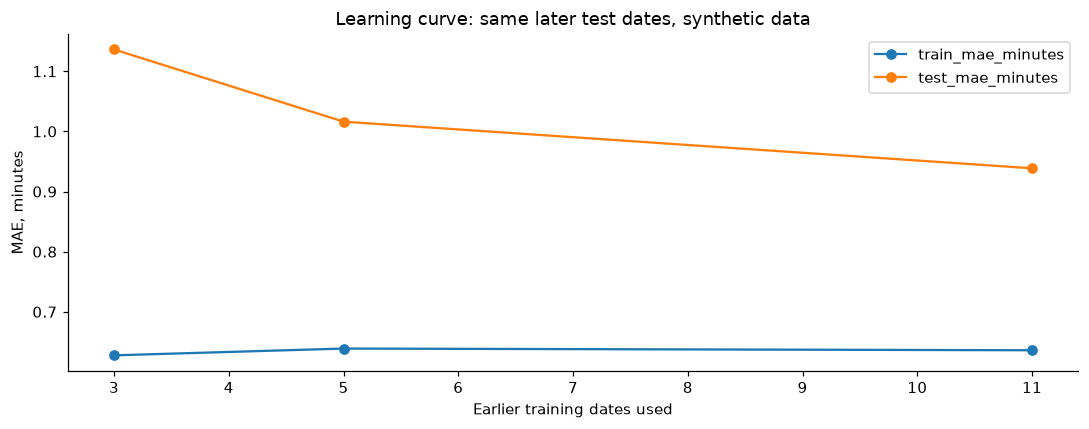

In [12]:
display(pd.Series({'QRF test MAE': report['mae_minutes'],
                   'Shuffled-label test MAE': report['shuffled_label_mae_minutes']})
        .to_frame('minutes'))
curve = pd.DataFrame(report['learning_curve'])
display(curve)
display(pd.DataFrame(report['permutation_importance']).round(4))
ax = curve.plot(x='training_days', y=['train_mae_minutes', 'test_mae_minutes'], marker='o')
ax.set(title='Learning curve: same later test dates, synthetic data',
       xlabel='Earlier training dates used', ylabel='MAE, minutes')
plt.tight_layout()
plt.show()

### Code cell 13: check that the notebook matches the server experiment

Our coursework should explain the model the backend actually uses. This cell
reads the saved results from the admin-panel experiment and matches each
test query by its stage, service, session and time. It compares the waiting
times, predicted ranges and baseline predictions with this notebook's run.

A maximum absolute difference of zero means the compared values match
exactly. The assertions allow only tiny numerical differences and check the
training and testing dates too. Another fingerprint check confirms that the
source file was left unchanged.

The cell saves a verification summary. Matching results shows that the
notebook reproduces the saved experiment; it does not test the current live
API or establish how well the model works on future field data.

In [13]:
saved = json.loads((ROOT / 'docs/evidence/evaluation.json').read_text(encoding='utf-8'))
saved_predictions = pd.read_csv(ROOT / 'docs/evidence/held-out-predictions.csv')
# Compare by query identity, not row position or platform-dependent model hash.
identity = ['stage_id', 'route_id', 'direction', 'session_id', 'query_at', 'day']
aligned = pred.merge(saved_predictions, on=identity, suffixes=('_new', '_admin'),
                     how='outer', validate='one_to_one', indicator=True)
assert aligned['_merge'].eq('both').all()
fields = ['actual_wait_minutes', 'lower_minutes', 'median_minutes', 'upper_minutes',
          'historical_median_minutes', 'last_headway_minutes']
differences = {col: float(np.max(np.abs(aligned[col + '_new'] - aligned[col + '_admin'])))
               for col in fields}
# Same locked model dependencies and deterministic seed should reproduce the run.
for col in fields:
    np.testing.assert_allclose(aligned[col + '_new'], aligned[col + '_admin'],
                               rtol=1e-9, atol=1e-9)
assert report['train_days'] == saved['train_days']
assert report['test_days'] == saved['test_days']
display(pd.Series(differences, name='maximum absolute difference').to_frame())
verification = {'data_kind': provenance['data_kind'], 'source_sha256': source_hash,
                'original_file_unchanged': hashlib.sha256(DATA.read_bytes()).hexdigest() == source_hash,
                'accepted_arrivals': len(cleaned), 'rejected_source_arrivals': len(rejected),
                'teaching_only_rejections': len(demo_rejected),
                'train_queries': len(fit_rows), 'test_queries': len(test_rows),
                'notebook_model_version': report['model_version'],
                'admin_model_version': saved['model_version'],
                'prediction_differences': differences,
                'mae_minutes': report['mae_minutes'],
                'rmse_minutes': comparison.loc['QRF median', 'RMSE (min)'],
                'r_squared': comparison.loc['QRF median', 'R²'],
                'within_one_minute_percent': comparison.loc['QRF median', 'Within ±1 min (%)'],
                'coverage': report['empirical_coverage']}
assert verification['original_file_unchanged']
(OUT / 'notebook_verification.json').write_text(json.dumps(verification, indent=2),
                                             encoding='utf-8')
print('All cleaning, split, metric and saved-admin-prediction checks passed.')

,maximum absolute difference
actual_wait_minutes,0.0
lower_minutes,0.0
median_minutes,0.0
upper_minutes,0.0
historical_median_minutes,0.0
last_headway_minutes,0.0


All cleaning, split, metric and saved-admin-prediction checks passed.


## 9. Study the real Nairobi network dataset

The [Digital Matatus project](https://www.digitalmatatus.com/about.html) collected
Nairobi routes and stops with mobile devices. Its [official download page](https://www.digitalmatatus.com/map.html)
provides the 2019 GTFS network feed used here. GTFS is a format for sharing transit
stops, routes, trips and service information.

We keep this network data separate from the arrival dataset used above. It helps
us identify mapped boarding places and route connections for the mobile app.
Its service calendar ends in 2020, so the records need field checking before use
as a current catalog. Its stop times and frequency rows describe a static feed;
they do not provide dated, repeated observations for the waiting-time experiment.

The preparation script checks stop IDs, coordinates and references between tables.
It selects a study rectangle around the CBD, latitude −1.295 to −1.275 and longitude
36.815 to 36.835. This rectangle is an analysis filter, not an official boundary.
If the local files are missing, run the preparation command in [the setup guide](README.md).

### Code cell 14: load the real Nairobi network

This dataset tells us where stops were mapped and which routes were linked to
them. Its 4,284 stop records and 136 routes come from the official historical
Digital Matatus feed. Some stop records represent station areas and others
represent individual boarding points, so the count is not a count of unique
station names.

The preparation script checks coordinates and connections between the tables.
Here we read its results, check the archive fingerprint, and count 85 stops
and 93 linked routes within our CBD study rectangle. The leading zeros in
stop IDs are preserved because they are identifiers, not quantities.

This supports NganyaFlow's stage browsing and route information. The feed does
not tell us when successive vehicles actually arrived on particular dates,
so it cannot supply the training answers used in our waiting-time test.

In [14]:
REAL = ROOT / 'server/data/external/digital-matatus-2019'
if not (REAL / 'processed/stops.csv').is_file():
    raise FileNotFoundError('Prepare real data first: python server/scripts/prepare_real_dataset.py')
real_source = json.loads((REAL / 'source.json').read_text(encoding='utf-8'))
archive_hash = hashlib.sha256((REAL / 'source/GTFS_FEED_2019.zip').read_bytes()).hexdigest()
assert archive_hash == real_source['archive_sha256']
real_stops = pd.read_csv(REAL / 'processed/stops.csv',
                         dtype={'stop_id': 'string', 'parent_station': 'string'})
real_routes = pd.read_csv(REAL / 'processed/routes.csv', dtype='string')
cbd_stops = pd.read_csv(REAL / 'processed/cbd_stops.csv',
                        dtype={'stop_id': 'string', 'parent_station': 'string'})
cbd_routes = pd.read_csv(REAL / 'processed/cbd_routes.csv', dtype='string')
cbd_links = pd.read_csv(REAL / 'processed/cbd_route_stops.csv', dtype='string')
assert real_stops['stop_id'].is_unique and real_routes['route_id'].is_unique
assert len(real_stops) == real_source['clean_stops']
assert len(cbd_stops) == real_source['cbd_stops']
assert len(cbd_routes) == real_source['cbd_routes']
assert cbd_links['stop_id'].isin(cbd_stops['stop_id']).all()
assert cbd_links['route_id'].isin(cbd_routes['route_id']).all()
assert real_source['wait_model_training_eligible'] is False
display(pd.Series({
    'Dataset': real_source['dataset_id'],
    'Source stops': real_source['source_rows']['stops'],
    'Accepted stops': len(real_stops),
    'Rejected stops': real_source['rejected_stops'],
    'Source routes': len(real_routes),
    'Stops in CBD study rectangle': len(cbd_stops),
    'Routes linked to those stops': len(cbd_routes),
    'Archive SHA256': archive_hash,
}).to_frame('value'))
display(real_stops.head())

,value
Dataset,digital-matatus-2019-network-v1
Source stops,4284
Accepted stops,4284
Rejected stops,0
Source routes,136
Stops in CBD study rectangle,85
Routes linked to those stops,93
Archive SHA256,c7fd6252011f22c376ad7e67423f1e81781e13bb6939a8...


,stop_id,stop_name,stop_lat,stop_lon,location_type,parent_station
0,0001RLW,Railways,-1.290884,36.828242,0.0,<NA>
1,0002KOJ,Koja,-1.281230,36.822596,1.0,<NA>
2,0003NGR,Ngara,-1.274395,36.823806,1.0,<NA>
3,0004ODN,Odeon,-1.282769,36.825032,1.0,<NA>
4,0005AMB,Kencom/Ambassadeur,-1.285963,36.826048,1.0,<NA>


### Code cell 15: connect the network data to our study locations

We find the source records named Kencom/Ambassadeur, Odeon and Railways, then
look up routes linked to those boarding points. Similar names can refer to
different platforms; keeping their original IDs avoids merging them by mistake.

The graph plots longitude from left to right and latitude from bottom to top.
Each point is a mapped stop, and the three labelled points help locate our
study areas. It is a coordinate plot, not a live map or a display of vehicles.

The final table gives the two datasets separate jobs. The network helps us
describe stages and routes; the arrival sequences let us train and check wait
predictions. The model's earlier error scores still belong to the arrival
experiment. Current route availability needs checking because the network
release is historical.

,stop_id,stop_name,stop_lat,stop_lon,parent_station
0,0001RLW,Railways,-1.290884,36.828242,<NA>
2,0004ODN,Odeon,-1.282769,36.825032,<NA>
3,0005AMB,Kencom/Ambassadeur,-1.285963,36.826048,<NA>
18,0210ENE,Odeon,-1.282972,36.824324,0004ODN
29,0212KUS,Odeon,-1.282740,36.824455,0004ODN
31,0212SNT,Odeon,-1.282831,36.824922,0004ODN
50,0411AAS,Railways,-1.289665,36.827261,<NA>
51,0411MEB,Kencom/Ambassadeur,-1.284634,36.826140,0005AMB
53,0412KNC,Kencom/Ambassadeur,-1.285663,36.824820,0005AMB
59,0502AMB,Kencom/Ambassadeur,-1.285400,36.825803,0005AMB


,stop_name,route_short_name,route_long_name
5,Odeon,107,Odeon-UN-Ruaka-Ndenderu
11,Odeon,11A,Odeon-Aga Khan-Highridge
14,Odeon,11B,Odeon-UN-Ruaka
29,Odeon,25,Odeon-Pangani-Alssops-Baba Dogo
40,Odeon,44G,Odeon-Pangani-Roysambu-Githurai-KU
44,Odeon,44Z,Odeon-Pangani-Roysambu-Zimmerman-KU
48,Odeon,45K,Odeon-Pangani-Roysabu-Githurai-KU
55,Odeon,49,Odeon-Pangani-Roysambu-Kasarani-Sunton
87,Odeon,25A,Odeon-Pangani-Alssops-Baba Dogo-Lucky Summer
126,Odeon,11C,Odeon-Pangani Flyover-Pangani Girls High Schoo...


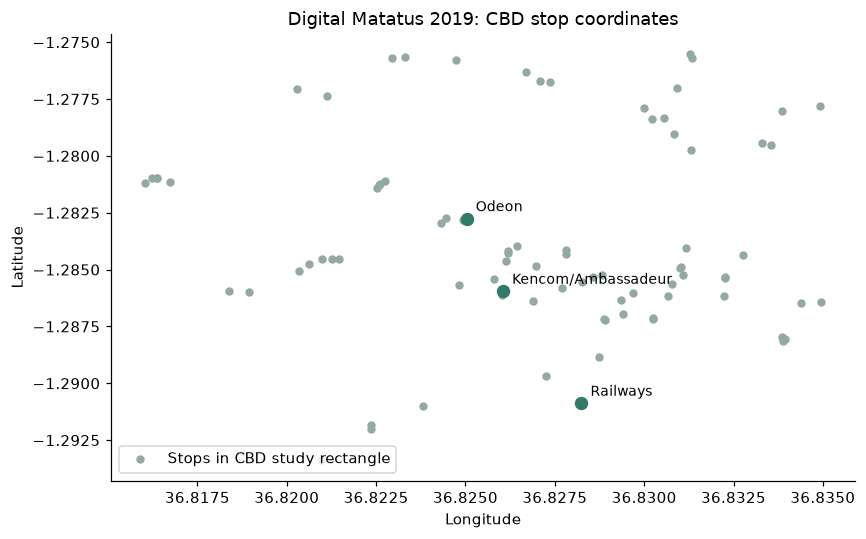

,dataset,records,role,used_for_wait_model
0,digital-matatus-2019-network-v1,"4,284 stops; 136 routes",Network context and mapped stage/route relatio...,False
1,nairobi-cbd-synthetic-v1,"1,049 arrivals; 84 sessions",Waiting-time training and held-out evaluation,True


The waiting-time scores above remain those of the arrival dataset.


In [15]:
# Retain source IDs: similarly named platforms are not automatically one stop.
focus = cbd_stops.loc[cbd_stops['stop_name'].str.contains(
    r'Kencom|Odeon|Railways', case=False, na=False)]
display(focus[['stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'parent_station']])
network = cbd_links.merge(cbd_stops[['stop_id', 'stop_name']],
                          on='stop_id', validate='many_to_one').merge(
    cbd_routes[['route_id', 'route_short_name', 'route_long_name']],
    on='route_id', validate='many_to_one')
focus_links = network.loc[network['stop_id'].isin(focus['stop_id'])]
display(focus_links[['stop_name', 'route_short_name', 'route_long_name']]
        .drop_duplicates().head(15))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cbd_stops['stop_lon'], cbd_stops['stop_lat'], s=20,
           color='#95a9a4', label='Stops in CBD study rectangle')
anchors = cbd_stops.loc[cbd_stops['stop_id'].isin(['0001RLW', '0004ODN', '0005AMB'])]
ax.scatter(anchors['stop_lon'], anchors['stop_lat'], s=60, color='#337968')
for row in anchors.itertuples():
    ax.annotate(row.stop_name, (row.stop_lon, row.stop_lat), xytext=(6, 5),
                textcoords='offset points', fontsize=9)
ax.set(title='Digital Matatus 2019: CBD stop coordinates',
       xlabel='Longitude', ylabel='Latitude')
ax.legend(loc='lower left')
fig.tight_layout()
fig.savefig(OUT / 'real_cbd_stops.png', bbox_inches='tight')
plt.show()
dataset_roles = pd.DataFrame([
    {'dataset': real_source['dataset_id'], 'records': f'{len(real_stops):,} stops; {len(real_routes)} routes',
     'role': 'Network context and mapped stage/route relationships',
     'used_for_wait_model': False},
    {'dataset': provenance['dataset_id'], 'records': f'{len(cleaned):,} arrivals; {len(sessions)} sessions',
     'role': 'Waiting-time training and held-out evaluation',
     'used_for_wait_model': True},
])
display(dataset_roles)
dataset_roles.to_csv(OUT / 'dataset_roles.csv', index=False)
print('The waiting-time scores above remain those of the arrival dataset.')

## 10. Results and limitations

All 1,049 arrivals from 84 sessions pass the cleaning checks. The separate
error example catches all seven added rows. Training uses 4,684 queries
from earlier dates, with 1,259 queries from the final three dates held out
for testing.

The QRF's MAE is about 0.939 minutes, compared with 2.211 minutes for the
historical median and 1.018 minutes for the last-headway baseline. Its
nominal 80% interval contains 80.06% of the test waits, with an average
width of about 3.10 minutes. Coverage varies between places, so the
overall figure should be read alongside the results for each stage.

These results cover three test dates, and queries within a session are
closely related. Treating all 1,259 queries as independent observations
would overstate the evidence. We therefore do not calculate a confidence
interval using that assumption or claim that coverage is established for
field use.

The dataset contains patterns designed for this learning exercise. Missing
arrivals, traffic changes, service changes and collection bias could alter
performance in practice. The label rules also leave out long gaps and
unobserved session tails. Predictions describe arrival waits and do not
guarantee an available seat.

Further tuning needs a separate set of validation dates, followed by a
fresh field test. Repeatedly tuning against the current test dates would
make them part of model development.

References: [Jupyter](https://jupyter.org/install),
[pandas datetime parsing](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html),
[QRF paper (Meinshausen, 2006)](https://www.jmlr.org/papers/v7/meinshausen06a.html),
[quantile-forest API](https://zillow.github.io/quantile-forest/generated/quantile_forest.RandomForestQuantileRegressor.html),
[scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).